# Analyse exploratoire du CSV SNCF

On cherche à comprendre le contenu du fichier, les évolutions des retards et les différences entre liaisons. Les calculs et les graphiques sont tous dans ce notebook.

Exécuter les cellules dans l'ordre, ou utiliser **Run > Run All Cells**. Le fichier CSV doit être dans le même dossier. Aucune cellule ne réécrit le CSV et aucune valeur n'est corrigée.

**Lancer en local :**
```bash
uv sync
uv run jupyter lab analyse_sncf.ipynb
```

**Lancer avec Docker :**
```bash
docker build -t analyse-sncf .
docker run --rm -p 127.0.0.1:8888:8888 analyse-sncf
```
Ouvrir le lien avec le jeton affiché dans le terminal. Avec Docker, télécharger le notebook depuis Jupyter pour conserver les modifications avant d'arrêter le conteneur.

## 1. Lire le fichier

Le séparateur est un point-virgule. Une observation représente un mois, un service et une liaison orientée.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.figsize"] = (10, 4)

df = pd.read_csv("regularite-mensuelle-tgv-aqst.csv", sep=";")
display(df.head())
print("Nombre de lignes :", df.shape[0])
print("Nombre de colonnes :", df.shape[1])

,Date,Service,Gare de départ,Gare d'arrivée,Durée moyenne du trajet,Nombre de circulations prévues,Nombre de trains annulés,Commentaire annulations,Nombre de trains en retard au départ,Retard moyen des trains en retard au départ,Retard moyen de tous les trains au départ,Commentaire retards au départ,Nombre de trains en retard à l'arrivée,Retard moyen des trains en retard à l'arrivée,Retard moyen de tous les trains à l'arrivée,Commentaire retards à l'arrivée,Nombre trains en retard > 15min,Retard moyen trains en retard > 15 (si liaison concurrencée par vol),Nombre trains en retard > 30min,Nombre trains en retard > 60min,Prct retard pour causes externes,Prct retard pour cause infrastructure,Prct retard pour cause gestion trafic,Prct retard pour cause matériel roulant,Prct retard pour cause gestion en gare et réutilisation de matériel,"Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)"
0,2018-01,National,BORDEAUX ST JEAN,PARIS MONTPARNASSE,141,870,5,NaN,289,11.25,3.69,NaN,147,28.44,6.51,NaN,110,6.51,44,8,36.13,31.09,10.92,15.97,5.04,0.84
1,2018-01,National,LE MANS,PARIS MONTPARNASSE,56,406,1,NaN,213,8.48,4.57,NaN,105,18.05,5.36,"Ce mois-ci, l'OD a été touchée par les inciden...",32,5.36,9,4,20.00,35.00,16.67,16.67,8.33,3.33
2,2018-01,National,PARIS MONTPARNASSE,LA ROCHELLE VILLE,166,226,0,NaN,21,6.24,0.29,NaN,19,24.74,2.94,NaN,11,2.94,6,1,22.22,27.78,16.67,16.67,5.56,11.11
3,2018-01,National,PARIS MONTPARNASSE,NANTES,124,508,3,NaN,71,7.24,0.73,NaN,58,33.73,5.29,NaN,39,5.29,18,8,33.33,22.22,16.67,20.37,5.56,1.85
4,2018-01,National,POITIERS,PARIS MONTPARNASSE,94,472,4,NaN,224,6.78,3.23,NaN,89,14.59,4.88,NaN,42,4.88,10,0,15.79,45.61,19.30,15.79,1.75,1.75


Nombre de lignes : 12907
Nombre de colonnes : 26


In [2]:
df.info()

print("\nPremier mois :", df["Date"].min())
print("Dernier mois :", df["Date"].max())
print("Nombre de mois :", df["Date"].nunique())
print("Nombre de liaisons :", df[["Gare de départ", "Gare d'arrivée"]].drop_duplicates().shape[0])

gares = pd.concat([df["Gare de départ"], df["Gare d'arrivée"]])
print("Nombre de gares :", gares.nunique())
display(df["Service"].value_counts().rename("observations"))

<class 'pandas.DataFrame'>
RangeIndex: 12907 entries, 0 to 12906
Data columns (total 26 columns):
 #   Column                                                                                       Non-Null Count  Dtype  
---  ------                                                                                       --------------  -----  
 0   Date                                                                                         12907 non-null  str    
 1   Service                                                                                      12907 non-null  str    
 2   Gare de départ                                                                               12907 non-null  str    
 3   Gare d'arrivée                                                                               12907 non-null  str    
 4   Durée moyenne du trajet                                                                      12907 non-null  int64  
 5   Nombre de circulations prévues             

Service
National         11339
International     1568
Name: observations, dtype: int64

## 2. Valeurs manquantes et doublons

Une colonne remplie peut quand même contenir des valeurs incohérentes. On regarde d'abord la complétude, puis les anomalies plus bas.

,nombre,pourcentage
Date,0,0.00
Service,0,0.00
Gare de départ,0,0.00
Gare d'arrivée,0,0.00
Durée moyenne du trajet,0,0.00
Nombre de circulations prévues,0,0.00
Nombre de trains annulés,0,0.00
Commentaire annulations,12907,100.00
Nombre de trains en retard au départ,0,0.00
Retard moyen des trains en retard au départ,0,0.00


Doublons complets : 0
Doublons sur mois, service et liaison : 0


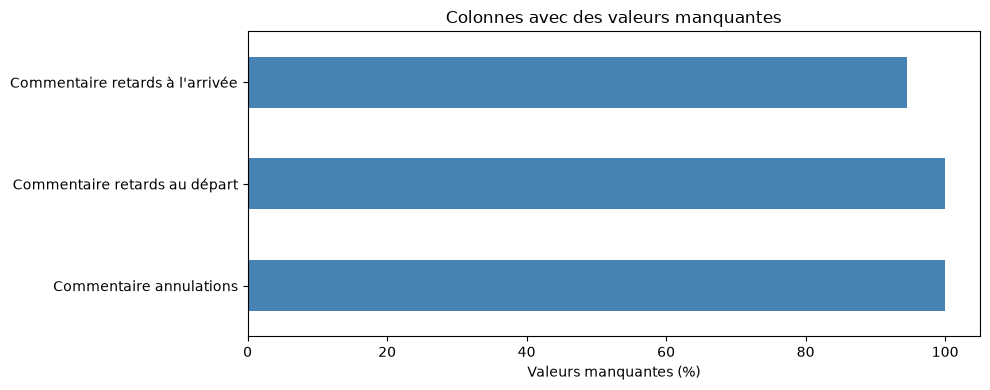

In [3]:
manquants = pd.DataFrame({
    "nombre": df.isna().sum(),
    "pourcentage": 100 * df.isna().mean()
})
display(manquants)

cle = ["Date", "Service", "Gare de départ", "Gare d'arrivée"]
print("Doublons complets :", df.duplicated().sum())
print("Doublons sur mois, service et liaison :", df.duplicated(cle).sum())

manquants.loc[manquants["nombre"] > 0, "pourcentage"].plot.barh(color="steelblue")
plt.title("Colonnes avec des valeurs manquantes")
plt.xlabel("Valeurs manquantes (%)")
plt.tight_layout()
plt.show()

In [4]:
# Une liaison peut apparaître avec deux services dans le même mois.
# On les affiche sans supprimer les lignes.
cle_liaison = ["Date", "Gare de départ", "Gare d'arrivée"]
plusieurs_services = df.loc[df.duplicated(cle_liaison, keep=False)]

print("Observations avec plusieurs services pour le même mois et la même liaison :", len(plusieurs_services))
display(plusieurs_services[cle].sort_values(cle_liaison).head(10))

commentaires = df.loc[df["Commentaire retards à l'arrivée"].notna()]
print("Commentaires à l'arrivée renseignés :", len(commentaires))
display(commentaires.groupby(commentaires["Date"].str[:4]).size().rename("commentaires"))

Observations avec plusieurs services pour le même mois et la même liaison : 84


,Date,Service,Gare de départ,Gare d'arrivée
11055,2025-07,National,BELLEGARDE (AIN),PARIS LYON
11130,2025-07,International,BELLEGARDE (AIN),PARIS LYON
11078,2025-07,International,CHAMBERY CHALLES LES EAUX,PARIS LYON
11137,2025-07,National,CHAMBERY CHALLES LES EAUX,PARIS LYON
11102,2025-07,International,DIJON VILLE,PARIS LYON
11138,2025-07,National,DIJON VILLE,PARIS LYON
11164,2025-07,International,LYON PART DIEU,MARSEILLE ST CHARLES
11173,2025-07,National,LYON PART DIEU,MARSEILLE ST CHARLES
11061,2025-07,National,MACON LOCHE,PARIS LYON
11080,2025-07,International,MACON LOCHE,PARIS LYON


Commentaires à l'arrivée renseignés : 698


Date
2018    457
2019    241
Name: commentaires, dtype: int64

## 3. Statistiques descriptives

Les valeurs sont conservées telles quelles, y compris les minima négatifs. Les retards moyens du fichier sont des moyennes mensuelles, pas les retards individuels des trains.

,count,mean,std,min,25%,50%,75%,max
Durée moyenne du trajet,12907.00,170.69,87.73,0.00,99.00,163.00,223.00,786.00
Nombre de circulations prévues,12907.00,273.44,184.12,0.00,151.00,231.00,365.00,1104.00
Nombre de trains annulés,12907.00,8.27,21.81,0.00,0.00,2.00,7.00,297.00
Commentaire annulations,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nombre de trains en retard au départ,12907.00,86.70,88.75,0.00,22.00,52.00,127.00,598.00
Retard moyen des trains en retard au départ,12907.00,12.60,11.58,0.00,6.43,10.70,16.23,316.19
Retard moyen de tous les trains au départ,12907.00,3.22,5.02,-229.27,1.25,2.40,4.09,115.05
Commentaire retards au départ,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nombre de trains en retard à l'arrivée,12907.00,38.87,32.45,0.00,16.00,30.00,53.00,376.00
Retard moyen des trains en retard à l'arrivée,12907.00,35.62,15.61,-40.11,26.09,33.90,42.91,299.60


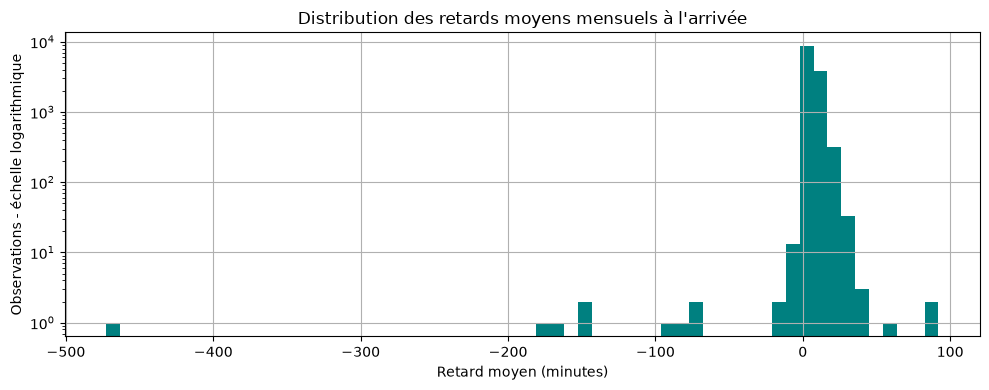

In [5]:
display(df.describe().T)

df["Retard moyen de tous les trains à l'arrivée"].hist(bins=60, color="teal")
plt.yscale("log")
plt.title("Distribution des retards moyens mensuels à l'arrivée")
plt.xlabel("Retard moyen (minutes)")
plt.ylabel("Observations - échelle logarithmique")
plt.tight_layout()
plt.show()

## 4. Indicateurs globaux

On calcule :
- **Effectifs** = circulations prévues - annulations.
- **Taux d'annulation** = somme des annulations / somme des circulations prévues.
- **Taux de retard** = somme des retards / somme des effectifs.
- **Retard moyen pondéré** = somme des moyennes mensuelles × leurs effectifs / somme des effectifs.

On utilise des ratios de sommes, pas une moyenne simple des taux. Les colonnes de calcul sont ajoutées à une copie en mémoire. Les effectifs négatifs restent dans les agrégats bruts et sont signalés à la fin.

In [6]:
analyse = df.copy()
analyse["date"] = pd.to_datetime(analyse["Date"])
analyse["annee"] = analyse["date"].dt.year
analyse["mois"] = analyse["date"].dt.month
analyse["effectifs"] = analyse["Nombre de circulations prévues"] - analyse["Nombre de trains annulés"]

# Ces produits servent uniquement à calculer les moyennes pondérées.
analyse["retard_pondere"] = analyse["Retard moyen de tous les trains à l'arrivée"] * analyse["effectifs"]
analyse["duree_ponderee"] = analyse["Durée moyenne du trajet"] * analyse["effectifs"]

prevus = analyse["Nombre de circulations prévues"].sum()
annules = analyse["Nombre de trains annulés"].sum()
effectifs = analyse["effectifs"].sum()
retards = analyse["Nombre de trains en retard à l'arrivée"].sum()

indicateurs = pd.Series({
    "Circulations prévues": prevus,
    "Annulations": annules,
    "Effectifs calculés": effectifs,
    "Retards à l'arrivée": retards,
    "Taux d'annulation (%)": 100 * annules / prevus,
    "Taux de retard arrivée (%)": 100 * retards / effectifs,
    "Taux de retard départ (%)": 100 * analyse["Nombre de trains en retard au départ"].sum() / effectifs,
    "Retard moyen arrivée pondéré (min)": analyse["retard_pondere"].sum() / effectifs,
    "Durée moyenne par observation (min)": analyse["Durée moyenne du trajet"].mean(),
    "Durée moyenne pondérée (min)": analyse["duree_ponderee"].sum() / effectifs,
}, name="valeur")
display(indicateurs)

print(f"Sur le périmètre du fichier : {100 * retards / effectifs:.2f} % de retards à l'arrivée.")
print(f"Les annulations représentent {100 * annules / prevus:.2f} % des circulations prévues.")

Circulations prévues                  3529337.00
Annulations                            106788.00
Effectifs calculés                    3422549.00
Retards à l'arrivée                    501757.00
Taux d'annulation (%)                       3.03
Taux de retard arrivée (%)                 14.66
Taux de retard départ (%)                  32.70
Retard moyen arrivée pondéré (min)          6.03
Durée moyenne par observation (min)       170.69
Durée moyenne pondérée (min)              145.08
Name: valeur, dtype: float64

Sur le périmètre du fichier : 14.66 % de retards à l'arrivée.
Les annulations représentent 3.03 % des circulations prévues.


Ces totaux portent sur les circulations enregistrées **par liaison**. Sans identifiant de train ni nombre de voyageurs, on ne peut pas compter les trains uniques ou mesurer la part des voyageurs touchés.

## 5. Évolution mensuelle

On compare les volumes et les taux pour repérer les mois particuliers. Un pic ne suffit pas à en expliquer la cause.

,prevus,annules,effectifs,retards,retards_15,retards_30,retards_60,somme_retard,taux_retard,taux_annulation,retard_moyen
date,,,,,,,,,,,
2018-01-01,35260,266,34994,5278,3496,1617,568,189095.80,15.08,0.75,5.40
2018-02-01,32419,733,31686,6941,4959,2389,819,265533.03,21.91,2.26,8.38
2018-03-01,35458,929,34529,5236,3415,1527,500,179639.60,15.16,2.62,5.20
2018-04-01,36243,11841,24402,4066,2647,1032,312,125628.88,16.66,32.67,5.15
2018-05-01,36111,8860,27251,4728,3195,1521,528,164549.87,17.35,24.54,6.04


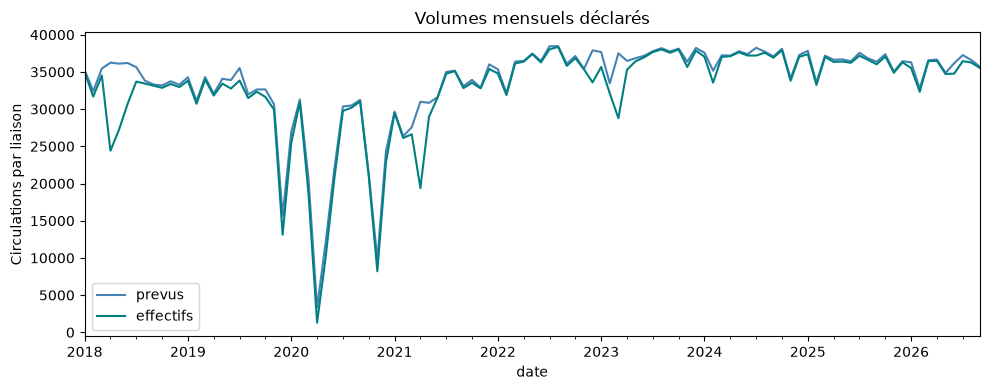

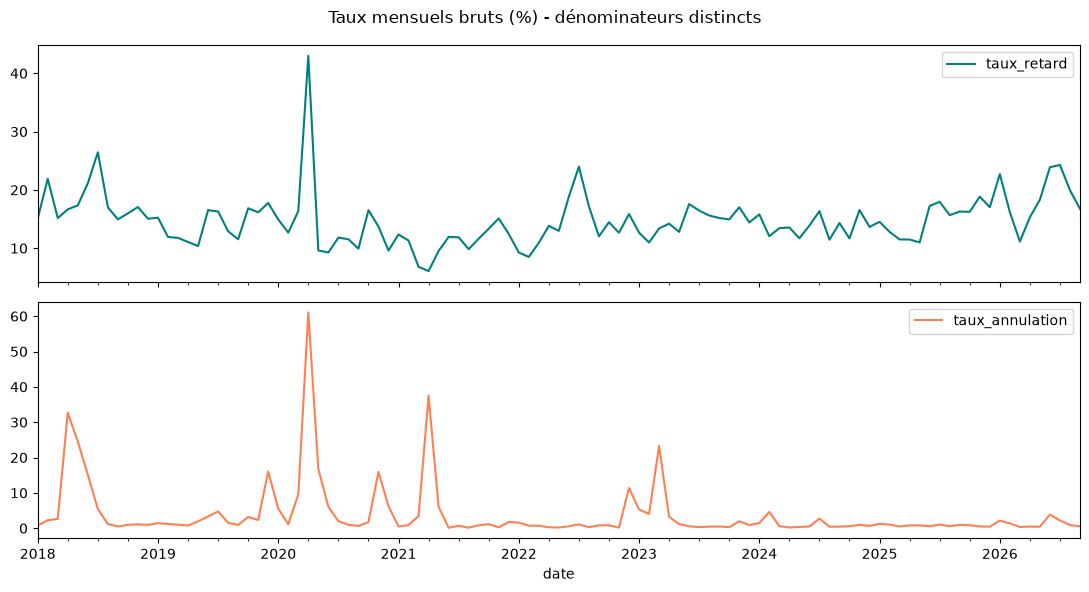

In [7]:
mensuel = analyse.groupby("date").agg(
    prevus=("Nombre de circulations prévues", "sum"),
    annules=("Nombre de trains annulés", "sum"),
    effectifs=("effectifs", "sum"),
    retards=("Nombre de trains en retard à l'arrivée", "sum"),
    retards_15=("Nombre trains en retard > 15min", "sum"),
    retards_30=("Nombre trains en retard > 30min", "sum"),
    retards_60=("Nombre trains en retard > 60min", "sum"),
    somme_retard=("retard_pondere", "sum"),
)
mensuel["taux_retard"] = 100 * mensuel["retards"] / mensuel["effectifs"]
mensuel["taux_annulation"] = 100 * mensuel["annules"] / mensuel["prevus"]
mensuel["retard_moyen"] = mensuel["somme_retard"] / mensuel["effectifs"]

display(mensuel.head())
mensuel[["prevus", "effectifs"]].plot(color=["steelblue", "teal"])
plt.title("Volumes mensuels déclarés")
plt.ylabel("Circulations par liaison")
plt.tight_layout()
plt.show()

mensuel[["taux_retard", "taux_annulation"]].plot(
    subplots=True, figsize=(11, 6), color=["teal", "coral"], sharex=True
)
plt.suptitle("Taux mensuels bruts (%) - dénominateurs distincts")
plt.tight_layout()
plt.show()

In [8]:
print("Les cinq plus forts taux d'annulation :")
display(mensuel.nlargest(5, "taux_annulation")[["prevus", "annules", "taux_annulation"]])

print("Les cinq plus forts taux de retard à l'arrivée :")
display(mensuel.nlargest(5, "taux_retard")[["effectifs", "retards", "taux_retard"]])

print("Attention : avril 2020 contient des effectifs individuels négatifs.")
print("Son ratio agrégé est calculable, mais son dénominateur est incohérent sur certaines lignes.")

Les cinq plus forts taux d'annulation :


,prevus,annules,taux_annulation
date,,,
2020-04-01,3325,2030,61.05
2021-04-01,30993,11611,37.46
2018-04-01,36243,11841,32.67
2018-05-01,36111,8860,24.54
2023-03-01,37496,8723,23.26


Les cinq plus forts taux de retard à l'arrivée :


,effectifs,retards,taux_retard
date,,,
2020-04-01,1295,557,43.01
2018-07-01,33696,8912,26.45
2026-07-01,36449,8852,24.29
2022-07-01,38036,9127,24.00
2026-06-01,34767,8304,23.88


Attention : avril 2020 contient des effectifs individuels négatifs.
Son ratio agrégé est calculable, mais son dénominateur est incohérent sur certaines lignes.


## 6. Évolution annuelle et comparaison à période identique

2026 ne contient que janvier à septembre. On présente les années disponibles, puis une comparaison limitée aux neuf mêmes mois pour chaque année.

,mois_observes,prevus,taux_retard,taux_annulation,retard_moyen
annee,,,,,
2018,12,414653,17.80,7.62,6.51
2019,12,378790,13.83,2.63,4.85
2020,12,263853,12.43,5.21,4.19
2021,12,383087,11.28,4.31,4.48
2022,12,437705,14.33,1.57,5.99
2023,12,445544,14.68,3.47,6.41
2024,12,444878,13.69,1.10,5.95
2025,12,437974,15.05,0.76,6.83
2026,9,322853,18.73,1.36,8.66


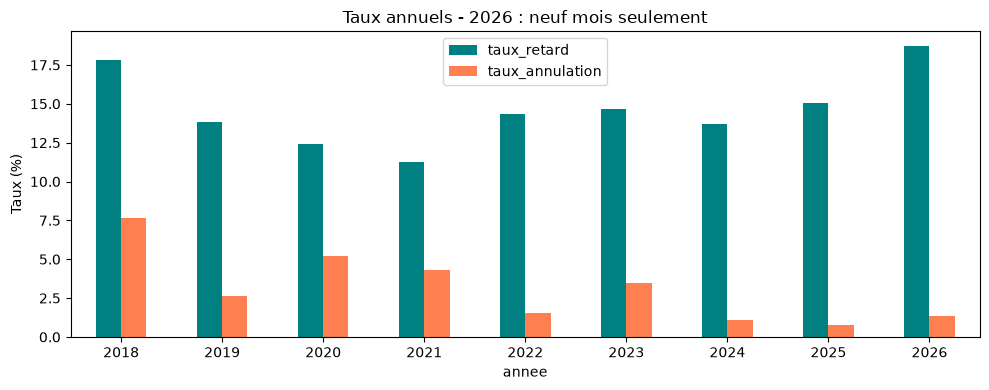

In [9]:
annuel = analyse.groupby("annee").agg(
    mois_observes=("Date", "nunique"),
    prevus=("Nombre de circulations prévues", "sum"),
    annules=("Nombre de trains annulés", "sum"),
    effectifs=("effectifs", "sum"),
    retards=("Nombre de trains en retard à l'arrivée", "sum"),
    retards_15=("Nombre trains en retard > 15min", "sum"),
    retards_30=("Nombre trains en retard > 30min", "sum"),
    retards_60=("Nombre trains en retard > 60min", "sum"),
    somme_retard=("retard_pondere", "sum"),
)
annuel["taux_retard"] = 100 * annuel["retards"] / annuel["effectifs"]
annuel["taux_annulation"] = 100 * annuel["annules"] / annuel["prevus"]
annuel["retard_moyen"] = annuel["somme_retard"] / annuel["effectifs"]
display(annuel[["mois_observes", "prevus", "taux_retard", "taux_annulation", "retard_moyen"]])

annuel[["taux_retard", "taux_annulation"]].plot.bar(color=["teal", "coral"])
plt.title("Taux annuels - 2026 : neuf mois seulement")
plt.ylabel("Taux (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,effectifs,retards,taux_retard
annee,,,
2018,283856,52295,18.42
2019,294162,38518,13.09
2020,198077,24293,12.26
2021,264847,27505,10.39
2022,325063,46614,14.34
2023,318513,45912,14.41
2024,331247,45145,13.63
2025,326393,46641,14.29
2026,318473,59638,18.73


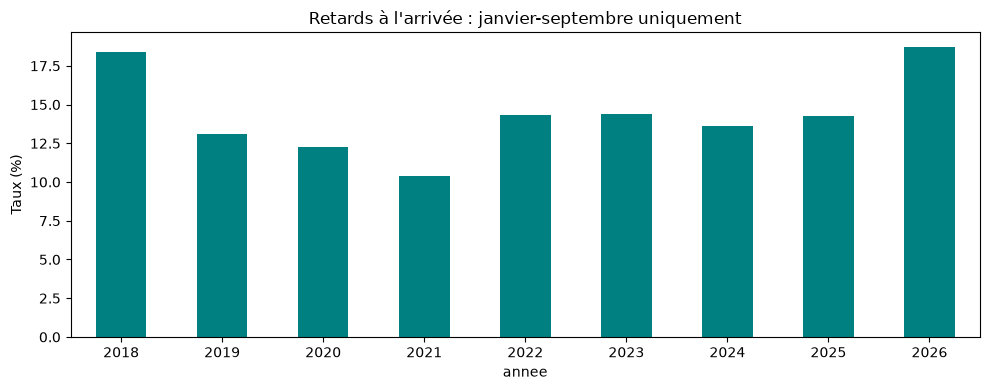

Entre janvier-septembre 2025 et 2026 : +4.44 points de pourcentage.
Les mois sont comparables, mais les volumes et leur répartition entre liaisons peuvent changer.


In [10]:
janvier_septembre = analyse.loc[analyse["mois"] <= 9]
comparaison = janvier_septembre.groupby("annee").agg(
    effectifs=("effectifs", "sum"),
    retards=("Nombre de trains en retard à l'arrivée", "sum"),
)
comparaison["taux_retard"] = 100 * comparaison["retards"] / comparaison["effectifs"]
display(comparaison)

comparaison["taux_retard"].plot.bar(color="teal")
plt.title("Retards à l'arrivée : janvier-septembre uniquement")
plt.ylabel("Taux (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

ecart = comparaison.loc[2026, "taux_retard"] - comparaison.loc[2025, "taux_retard"]
print(f"Entre janvier-septembre 2025 et 2026 : {ecart:+.2f} points de pourcentage.")
print("Les mois sont comparables, mais les volumes et leur répartition entre liaisons peuvent changer.")

## 7. Profil des mois de l'année

Pour le profil saisonnier, on prend seulement les années ayant douze mois. Cela décrit les mois observés sans isoler un effet causal de la saison.

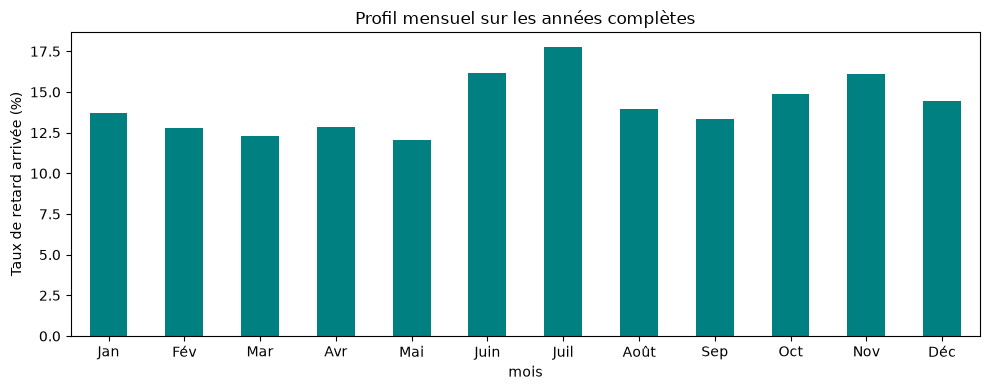

Mois au taux agrégé le plus élevé : Juil


In [11]:
annees_completes = annuel.index[annuel["mois_observes"] == 12]
donnees_completes = analyse.loc[analyse["annee"].isin(annees_completes)]

saisonnalite = donnees_completes.groupby("mois").agg(
    retards=("Nombre de trains en retard à l'arrivée", "sum"),
    effectifs=("effectifs", "sum"),
)
saisonnalite["taux_retard"] = 100 * saisonnalite["retards"] / saisonnalite["effectifs"]
noms_mois = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]

saisonnalite["taux_retard"].plot.bar(color="teal")
plt.xticks(range(12), noms_mois, rotation=0)
plt.ylabel("Taux de retard arrivée (%)")
plt.title("Profil mensuel sur les années complètes")
plt.tight_layout()
plt.show()

print("Mois au taux agrégé le plus élevé :", noms_mois[saisonnalite["taux_retard"].idxmax() - 1])

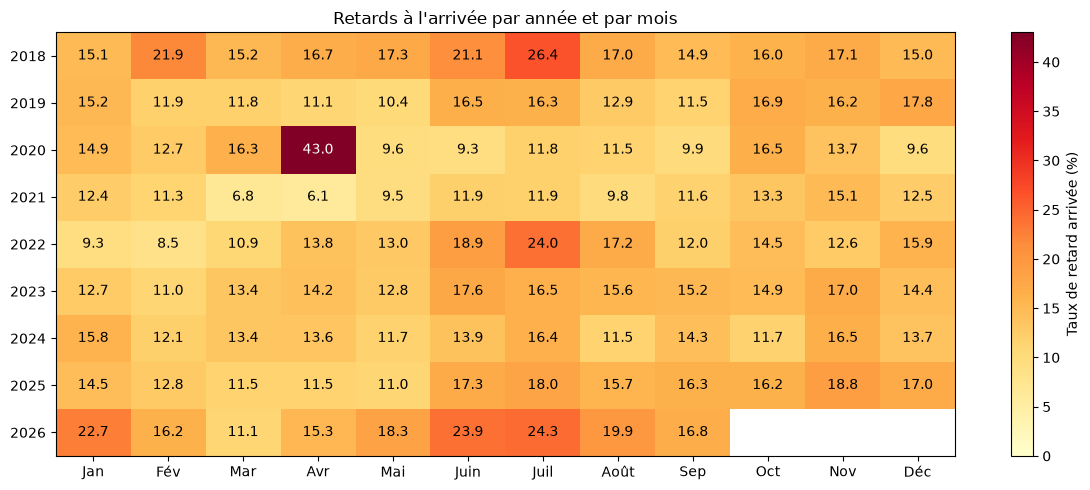

In [12]:
# La carte conserve aussi 2026. Les mois absents ne deviennent pas des zéros.
carte = mensuel[["taux_retard"]].copy()
carte["annee"] = carte.index.year
carte["mois"] = carte.index.month
carte = carte.pivot(index="annee", columns="mois", values="taux_retard")

plt.figure(figsize=(12, 5))
plt.imshow(carte, cmap="YlOrRd", aspect="auto", vmin=0)
plt.xticks(range(12), noms_mois)
plt.yticks(range(len(carte)), carte.index)
plt.colorbar(label="Taux de retard arrivée (%)")
for ligne in range(len(carte)):
    for colonne in range(12):
        valeur = carte.iloc[ligne, colonne]
        if pd.notna(valeur):
            couleur = "white" if valeur > 30 else "black"
            plt.text(colonne, ligne, f"{valeur:.1f}", ha="center", va="center", color=couleur)
plt.title("Retards à l'arrivée par année et par mois")
plt.tight_layout()
plt.show()

## 8. National et International

Les catégories sont utilisées telles qu'elles figurent dans le fichier. Les parcours et les volumes diffèrent : les écarts ne prouvent pas un effet du passage des frontières.

,prevus,effectifs,taux_retard,taux_annulation,retard_moyen
Service,,,,,
International,186439,180702,15.80,3.08,7.97
National,3342898,3241847,14.60,3.02,5.93


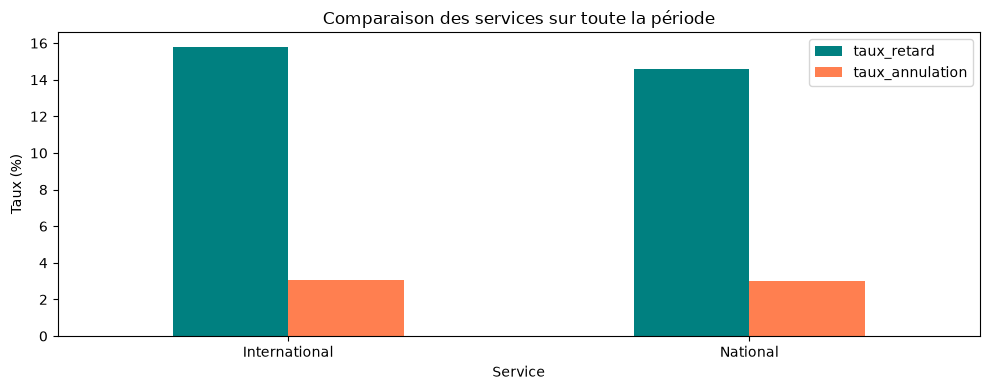

In [13]:
services = analyse.groupby("Service").agg(
    prevus=("Nombre de circulations prévues", "sum"),
    annules=("Nombre de trains annulés", "sum"),
    effectifs=("effectifs", "sum"),
    retards=("Nombre de trains en retard à l'arrivée", "sum"),
    somme_retard=("retard_pondere", "sum"),
)
services["taux_retard"] = 100 * services["retards"] / services["effectifs"]
services["taux_annulation"] = 100 * services["annules"] / services["prevus"]
services["retard_moyen"] = services["somme_retard"] / services["effectifs"]
display(services[["prevus", "effectifs", "taux_retard", "taux_annulation", "retard_moyen"]])

services[["taux_retard", "taux_annulation"]].plot.bar(color=["teal", "coral"])
plt.title("Comparaison des services sur toute la période")
plt.ylabel("Taux (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Comparaison des liaisons

Chaque sens est analysé séparément. Pour les mêmes gares, on réunit les services. On garde au moins 24 mois observés pour les classements, tout en affichant les volumes et les dates. Ce filtre sert uniquement au classement ; le CSV reste intact.

In [14]:
liaisons = analyse.groupby(["Gare de départ", "Gare d'arrivée"]).agg(
    mois_observes=("Date", "nunique"),
    debut=("Date", "min"),
    fin=("Date", "max"),
    prevus=("Nombre de circulations prévues", "sum"),
    annules=("Nombre de trains annulés", "sum"),
    effectifs=("effectifs", "sum"),
    retards=("Nombre de trains en retard à l'arrivée", "sum"),
    somme_retard=("retard_pondere", "sum"),
    somme_duree=("duree_ponderee", "sum"),
).reset_index()

liaisons["taux_retard"] = 100 * liaisons["retards"] / liaisons["effectifs"]
liaisons["taux_annulation"] = 100 * liaisons["annules"] / liaisons["prevus"]
liaisons["retard_moyen"] = liaisons["somme_retard"] / liaisons["effectifs"]
liaisons["duree_moyenne"] = liaisons["somme_duree"] / liaisons["effectifs"]
liaisons["liaison"] = liaisons["Gare de départ"] + " → " + liaisons["Gare d'arrivée"]

classement = liaisons.loc[liaisons["mois_observes"] >= 24].sort_values("taux_retard")
colonnes = ["liaison", "debut", "fin", "mois_observes", "effectifs", "taux_retard", "taux_annulation"]
print("Nombre de liaisons retenues :", len(classement))
display(classement[colonnes].head(10))
display(classement[colonnes].tail(10))

Nombre de liaisons retenues : 123


,liaison,debut,fin,mois_observes,effectifs,taux_retard,taux_annulation
57,PARIS EST → NANCY,2018-01,2026-09,105,27407,8.36,2.65
74,PARIS LYON → LYON PART DIEU,2018-01,2026-09,105,62665,8.37,2.28
8,BESANCON FRANCHE COMTE TGV → PARIS LYON,2018-01,2026-09,105,16888,8.41,2.80
22,LAUSANNE → PARIS LYON,2018-01,2026-09,105,13313,8.53,2.92
129,ZURICH → PARIS LYON,2018-01,2026-09,104,13383,8.75,2.35
89,PARIS MONTPARNASSE → BREST,2018-01,2026-09,105,24754,9.01,3.79
12,BREST → PARIS MONTPARNASSE,2018-01,2026-09,105,25933,9.10,3.22
41,MARSEILLE ST CHARLES → MADRID,2018-01,2022-12,45,848,9.20,7.63
68,PARIS LYON → DIJON VILLE,2018-01,2026-09,105,37804,9.23,2.49
90,PARIS MONTPARNASSE → LA ROCHELLE VILLE,2018-01,2026-09,105,21123,9.82,3.34


,liaison,debut,fin,mois_observes,effectifs,taux_retard,taux_annulation
39,MARSEILLE ST CHARLES → LILLE,2018-01,2026-09,105,19360,21.98,3.56
4,ARRAS → PARIS NORD,2018-01,2026-09,105,41504,22.01,4.23
15,DOUAI → PARIS NORD,2018-01,2026-09,105,16729,22.13,4.49
31,LYON PART DIEU → MARSEILLE ST CHARLES,2018-01,2026-09,105,45437,22.62,3.71
60,PARIS EST → STUTTGART,2018-01,2026-09,105,12351,23.57,3.49
30,LYON PART DIEU → MARNE LA VALLEE,2018-01,2026-09,105,31187,25.41,4.19
35,MACON LOCHE → PARIS LYON,2018-01,2026-09,105,22344,26.41,3.10
29,LYON PART DIEU → LILLE,2018-01,2026-09,105,28919,26.45,4.13
13,CHAMBERY CHALLES LES EAUX → PARIS LYON,2018-01,2026-09,105,21791,27.31,3.27
20,ITALIE → PARIS LYON,2018-01,2026-09,101,6894,33.04,4.36


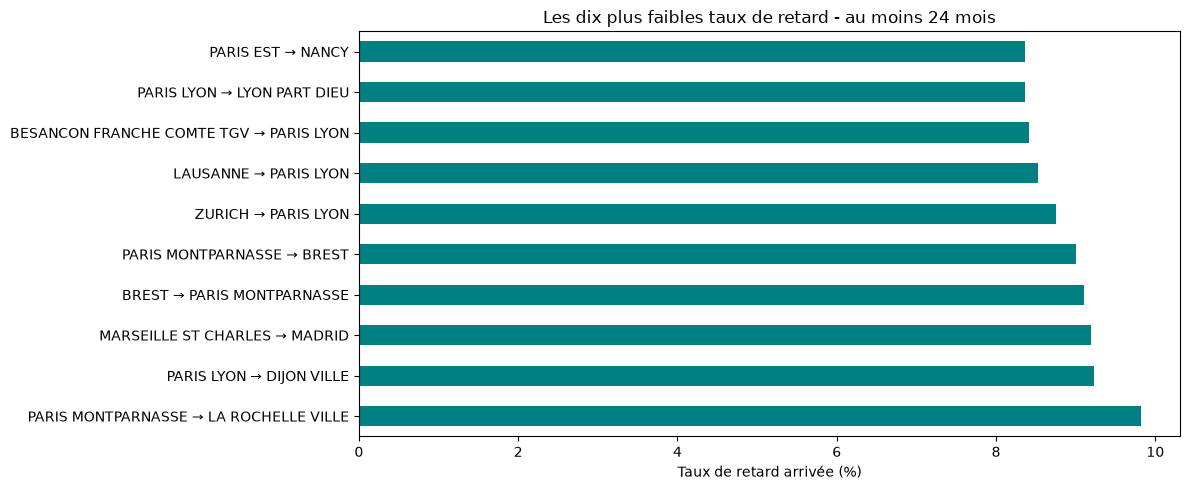

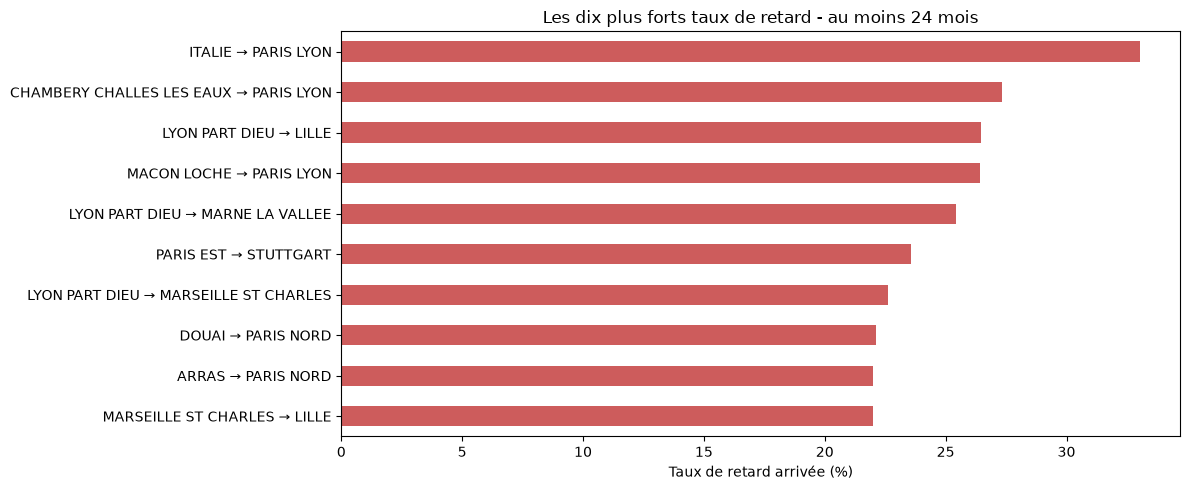

In [15]:
meilleures = classement.head(10).sort_values("taux_retard", ascending=False)
meilleures.plot.barh(x="liaison", y="taux_retard", color="teal", legend=False, figsize=(12, 5))
plt.title("Les dix plus faibles taux de retard - au moins 24 mois")
plt.xlabel("Taux de retard arrivée (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

pires = classement.tail(10)
pires.plot.barh(x="liaison", y="taux_retard", color="indianred", legend=False, figsize=(12, 5))
plt.title("Les dix plus forts taux de retard - au moins 24 mois")
plt.xlabel("Taux de retard arrivée (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

,liaison,debut,fin,mois_observes,effectifs,taux_retard,taux_annulation
16,DUNKERQUE → PARIS NORD,2018-01,2026-09,105,17162,12.15,4.20
4,ARRAS → PARIS NORD,2018-01,2026-09,105,41504,22.01,4.23
104,PARIS NORD → DUNKERQUE,2018-01,2026-09,105,18191,11.18,4.33
20,ITALIE → PARIS LYON,2018-01,2026-09,101,6894,33.04,4.36
15,DOUAI → PARIS NORD,2018-01,2026-09,105,16729,22.13,4.49
11,BORDEAUX ST JEAN → TOURCOING,2018-01,2026-09,103,2582,14.87,4.62
46,MONTPELLIER → LYON PART DIEU,2018-01,2026-09,105,19746,17.33,4.79
82,PARIS LYON → SAINT ETIENNE CHATEAUCREUX,2018-01,2026-09,105,10247,13.62,5.51
41,MARSEILLE ST CHARLES → MADRID,2018-01,2022-12,45,848,9.20,7.63
36,MADRID → MARSEILLE ST CHARLES,2018-01,2022-12,45,852,19.95,8.29


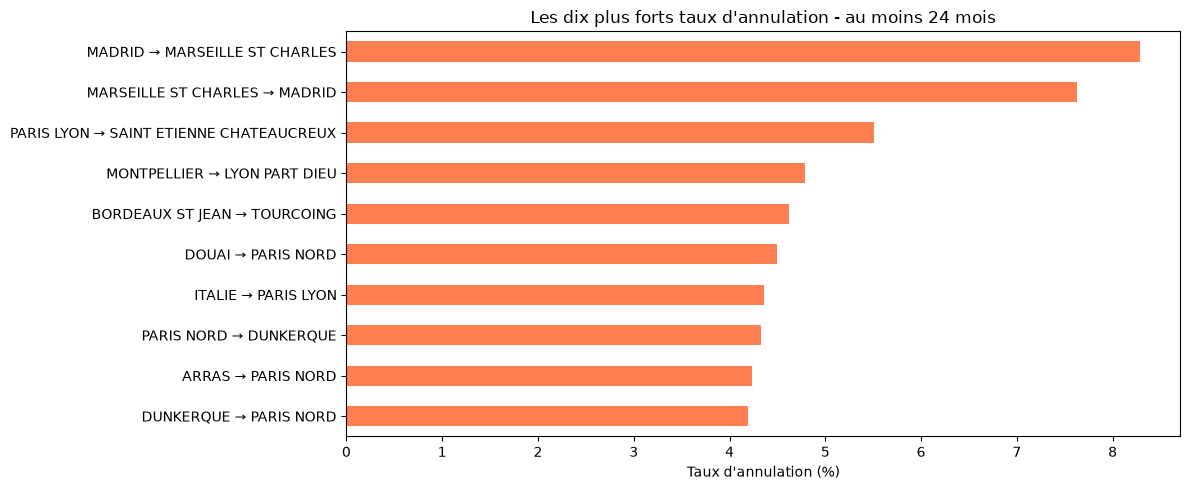

Un faible taux de retard n'implique pas un faible taux d'annulation.
Vérifier les périodes : certaines liaisons ne sont plus présentes en 2026.


In [16]:
plus_annulees = classement.nlargest(10, "taux_annulation").sort_values("taux_annulation")
display(plus_annulees[colonnes])

plus_annulees.plot.barh(
    x="liaison", y="taux_annulation", color="coral", legend=False, figsize=(12, 5)
)
plt.title("Les dix plus forts taux d'annulation - au moins 24 mois")
plt.xlabel("Taux d'annulation (%)")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Un faible taux de retard n'implique pas un faible taux d'annulation.")
print("Vérifier les périodes : certaines liaisons ne sont plus présentes en 2026.")

## 10. Durée du trajet et retards

Chaque point représente une liaison ayant au moins 24 mois. Le graphique sert à repérer une éventuelle association, sans conclure qu'une durée plus longue cause davantage de retards. Le CSV ne donne pas un seuil de retard uniforme permettant de rendre tous les parcours strictement comparables.

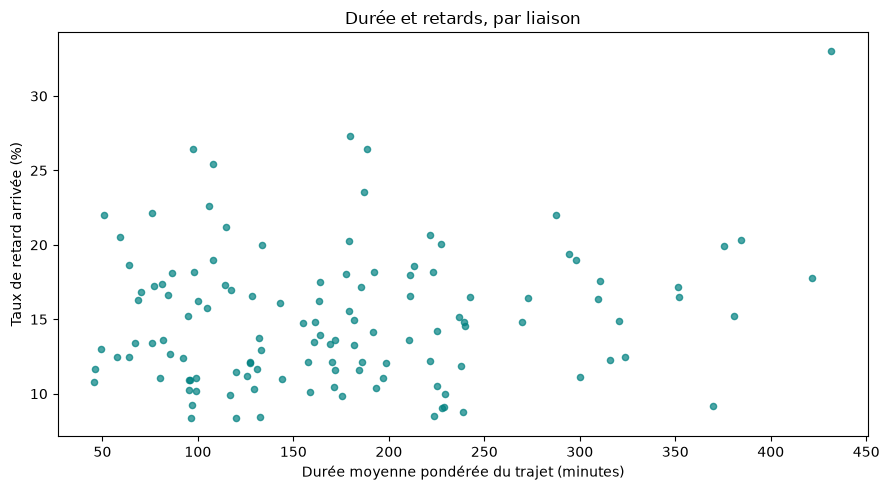

In [17]:
classement.plot.scatter(
    x="duree_moyenne", y="taux_retard", color="teal", alpha=0.7, figsize=(9, 5)
)
plt.xlabel("Durée moyenne pondérée du trajet (minutes)")
plt.ylabel("Taux de retard arrivée (%)")
plt.title("Durée et retards, par liaison")
plt.tight_layout()
plt.show()

## 11. Retards supérieurs à 15, 30 et 60 minutes

Ces comptages devraient être emboîtés si leur périmètre est identique. Certaines lignes ne respectent pas cette propriété. On montre les séries brutes sans fabriquer de tranches par soustraction.

,retards_15,retards_30,retards_60
annee,,,
2018,12.15,5.57,1.95
2019,9.58,4.48,1.71
2020,8.22,3.69,1.17
2021,8.29,4.10,1.46
2022,10.54,5.16,1.91
2023,10.79,5.36,2.14
2024,9.80,4.67,1.82
2025,11.32,4.59,3.09
2026,14.35,7.58,3.12


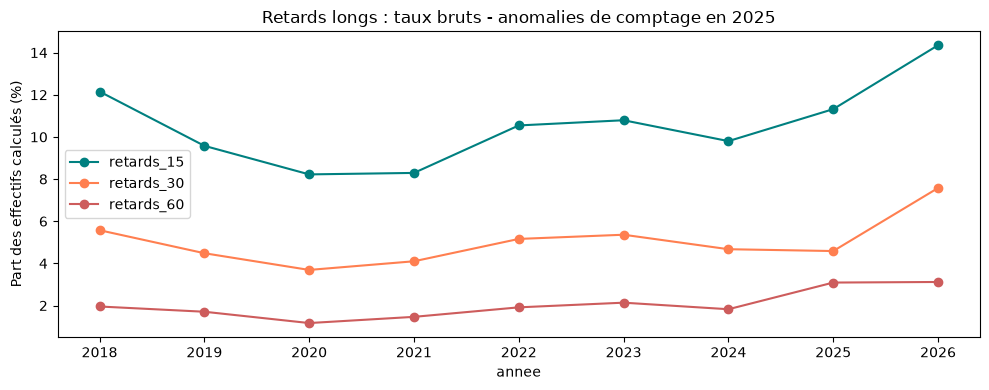

In [18]:
seuils = annuel[["retards_15", "retards_30", "retards_60"]].copy()
seuils = 100 * seuils.div(annuel["effectifs"], axis=0)
display(seuils)

seuils.plot(marker="o", color=["teal", "coral", "indianred"])
plt.title("Retards longs : taux bruts - anomalies de comptage en 2025")
plt.ylabel("Part des effectifs calculés (%)")
plt.tight_layout()
plt.show()

## 12. Causes déclarées

Pour résumer les pourcentages du fichier, on les pondère ici par le nombre de retards à l'arrivée. Le CSV ne documente pas précisément le dénominateur opérationnel de ces causes : il s'agit d'une convention de calcul. On ne force pas leur somme à 100 %.

,cause,part_ponderee
5,Prise en compte voyageurs,8.05
4,Gestion en gare / matériel,9.25
3,Matériel roulant,18.94
1,Infrastructure,20.47
2,Gestion du trafic,20.70
0,Causes externes,22.19


Somme des parts : 99.59 %


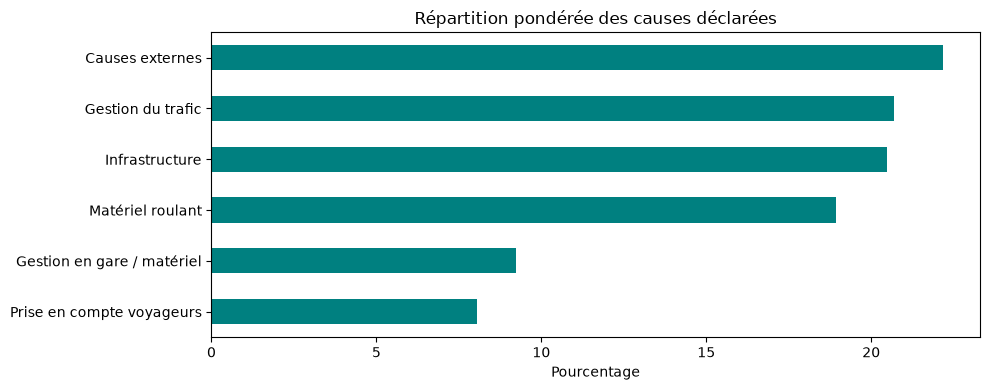

In [19]:
colonnes_causes = [
    "Prct retard pour causes externes",
    "Prct retard pour cause infrastructure",
    "Prct retard pour cause gestion trafic",
    "Prct retard pour cause matériel roulant",
    "Prct retard pour cause gestion en gare et réutilisation de matériel",
    "Prct retard pour cause prise en compte voyageurs (affluence, gestions PSH, correspondances)",
]
noms_causes = [
    "Causes externes", "Infrastructure", "Gestion du trafic",
    "Matériel roulant", "Gestion en gare / matériel", "Prise en compte voyageurs"
]

poids = df["Nombre de trains en retard à l'arrivée"]
parts = []
for colonne in colonnes_causes:
    moyenne = (df[colonne] * poids).sum() / poids.sum()
    parts.append(moyenne)

causes = pd.DataFrame({"cause": noms_causes, "part_ponderee": parts})
causes = causes.sort_values("part_ponderee")
display(causes)
print("Somme des parts :", round(causes["part_ponderee"].sum(), 2), "%")

causes.plot.barh(x="cause", y="part_ponderee", color="teal", legend=False)
plt.title("Répartition pondérée des causes déclarées")
plt.xlabel("Pourcentage")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 13. Anomalies et limites du CSV

On repère les lignes concernées sans les corriger ni les supprimer. Une moyenne négative sur **tous les trains** peut représenter une avance ; un nombre de trains négatif est en revanche incohérent.

,observations
Moyenne des trains en retard arrivée négative,2
Nombre > 30 min supérieur au nombre > 15 min,3
Effectifs nuls,10
Nombre > 15 min supérieur aux retards arrivée,31
Nombre > 30 min négatif,43
Effectifs négatifs,63
Durée de trajet nulle,73
Moyenne tous trains arrivée négative (à examiner),122
Somme des causes différente de 100 %,282
Nombre > 60 min supérieur au nombre > 30 min,354


Une observation peut être concernée par plusieurs contrôles.


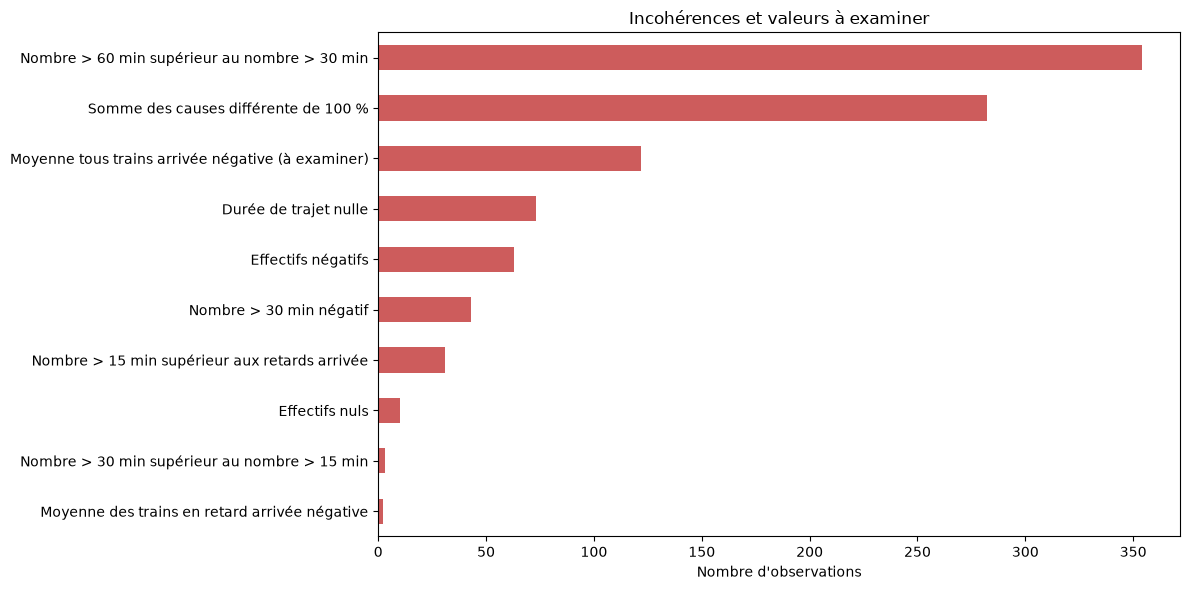

In [20]:
controles = pd.DataFrame(index=df.index)
controles["Effectifs négatifs"] = analyse["effectifs"] < 0
controles["Effectifs nuls"] = analyse["effectifs"] == 0
controles["Nombre > 30 min négatif"] = df["Nombre trains en retard > 30min"] < 0
controles["Nombre > 60 min supérieur au nombre > 30 min"] = (
    df["Nombre trains en retard > 60min"] > df["Nombre trains en retard > 30min"]
)
controles["Nombre > 30 min supérieur au nombre > 15 min"] = (
    df["Nombre trains en retard > 30min"] > df["Nombre trains en retard > 15min"]
)
controles["Nombre > 15 min supérieur aux retards arrivée"] = (
    df["Nombre trains en retard > 15min"] > df["Nombre de trains en retard à l'arrivée"]
)
controles["Moyenne des trains en retard arrivée négative"] = (
    df["Retard moyen des trains en retard à l'arrivée"] < 0
)
controles["Moyenne tous trains arrivée négative (à examiner)"] = (
    df["Retard moyen de tous les trains à l'arrivée"] < 0
)
controles["Durée de trajet nulle"] = df["Durée moyenne du trajet"] == 0
controles["Somme des causes différente de 100 %"] = (
    df[colonnes_causes].sum(axis=1) - 100
).abs() > 0.1

resume = controles.sum().sort_values()
display(resume.to_frame("observations"))
print("Une observation peut être concernée par plusieurs contrôles.")

resume.plot.barh(color="indianred", figsize=(12, 6))
plt.title("Incohérences et valeurs à examiner")
plt.xlabel("Nombre d'observations")
plt.tight_layout()
plt.show()

In [21]:
# Exemples concrets : le code permet de retrouver les lignes dans le CSV.
colonnes_exemples = [
    "Date", "Service", "Gare de départ", "Gare d'arrivée",
    "Nombre de circulations prévues", "Nombre de trains annulés",
    "Nombre trains en retard > 30min", "Nombre trains en retard > 60min",
]
print("Exemples de comptages négatifs :")
display(df.loc[controles["Nombre > 30 min négatif"], colonnes_exemples].head())

print("Mois concernés par les comptages négatifs :")
display(df.loc[controles["Nombre > 30 min négatif"], "Date"].value_counts().sort_index())

print("Exemples d'annulations supérieures aux prévisions :")
display(df.loc[controles["Effectifs négatifs"], colonnes_exemples].head())

print("Moyennes négatives de trains annoncés en retard :")
display(df.loc[controles["Moyenne des trains en retard arrivée négative"], [
    "Date", "Gare de départ", "Gare d'arrivée",
    "Retard moyen des trains en retard à l'arrivée"
]])

Exemples de comptages négatifs :


,Date,Service,Gare de départ,Gare d'arrivée,Nombre de circulations prévues,Nombre de trains annulés,Nombre trains en retard > 30min,Nombre trains en retard > 60min
10326,2025-01,International,LAUSANNE,PARIS LYON,172,10,-4,9
10329,2025-01,National,DIJON VILLE,PARIS LYON,426,4,-1,30
10330,2025-01,National,DOUAI,PARIS NORD,167,2,-1,9
10357,2025-01,National,LE MANS,PARIS MONTPARNASSE,472,5,-1,30
10358,2025-01,National,MARSEILLE ST CHARLES,MARNE LA VALLEE,296,0,-2,17


Mois concernés par les comptages négatifs :


Date
2025-01    18
2025-02    15
2025-03    10
Name: count, dtype: int64

Exemples d'annulations supérieures aux prévisions :


,Date,Service,Gare de départ,Gare d'arrivée,Nombre de circulations prévues,Nombre de trains annulés,Nombre trains en retard > 30min,Nombre trains en retard > 60min
3406,2020-04,National,PARIS MONTPARNASSE,ST MALO,0,8,0,0
3407,2020-04,National,PARIS MONTPARNASSE,TOURS,0,9,0,0
3409,2020-04,National,NANTES,STRASBOURG,0,2,0,0
3411,2020-04,National,PARIS NORD,DOUAI,0,12,0,0
3412,2020-04,National,DUNKERQUE,PARIS NORD,0,15,0,0


Moyennes négatives de trains annoncés en retard :


,Date,Gare de départ,Gare d'arrivée,Retard moyen des trains en retard à l'arrivée
2824,2019-11,MONTPELLIER,PARIS LYON,-30.51
2877,2019-11,NIMES,PARIS LYON,-40.11


## Ce que cette exploration met en évidence

- Le CSV couvre 105 mois et 130 liaisons orientées. La couverture et les volumes doivent accompagner les comparaisons.
- Les taux globaux bruts sont d'environ **14,66 % de retards à l'arrivée** et **3,03 % d'annulations**.
- À période janvier-septembre identique, le taux de retard passe de **14,29 % en 2025 à 18,73 % en 2026**.
- Les résultats varient selon les mois, les services et les liaisons. Retards et annulations décrivent deux aspects différents.
- **63 lignes** donnent un effectif négatif et **43 lignes** ont un nombre négatif de retards supérieurs à 30 minutes. Les calculs précédents conservent ces anomalies.
- Les données mensuelles ne permettent pas d'identifier un train, un horaire ou le nombre de voyageurs concernés. Les associations observées n'expliquent pas leurs causes.

Tous ces résultats proviennent des cellules ci-dessus. Aucun nettoyage ni fichier de données corrigées n'a été produit.